In [48]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

Carrega Dataset

In [49]:
df = pd.read_csv('../kc_house_data.csv')
df = df.rename(columns={
    "date": "data_venda",
    "price": "preco",
    "bedrooms": "quartos",
    "bathrooms": "banheiros",
    "sqft_living": "area_habitavel",
    "sqft_lot": "area_terreno",
    "floors": "andares",
    "waterfront": "frente_agua",
    "view": "vista",
    "condition": "condicao",
    "grade": "padrao_construcao",
    "sqft_above": "area_acima_solo",
    "sqft_basement": "area_porao",
    "yr_built": "ano_construcao",
    "yr_renovated": "ano_reforma",
    "zipcode": "codigo_postal",
    "lat": "latitude",
    "long": "longitude",
    "sqft_living15": "area_habitavel_vizinhos",
    "sqft_lot15": "area_terreno_vizinhos"
})

Teste com todas as variáveis numéricas do dataset

In [50]:
X = df.drop(columns=["preco"])
X = X.select_dtypes(include="number")
y = df["preco"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print(f"MAE: R$ {mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: R$ {mean_squared_error(y_test, y_pred)**0.5:,.2f}")
print(f"R²: {r2_score(y_test, y_pred):.4f}")

MAE: R$ 238,944.00
RMSE: R$ 387,314.36
R²: 0.0077


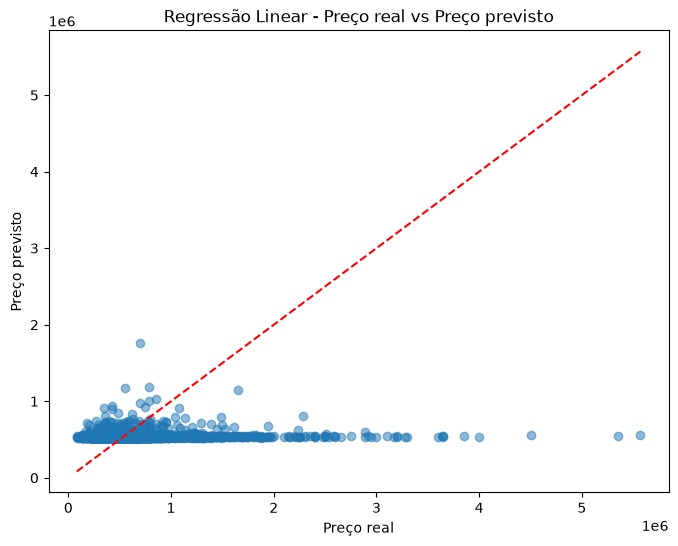

In [51]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Preço real")
plt.ylabel("Preço previsto")
plt.title("Regressão Linear - Preço real vs Preço previsto")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

Teste com as variáveis selecionadas a análise exploratória (area_habitavel, padrao_construcao, area_habitavel_vizinhos)

In [52]:
X = df[[
    "area_habitavel",
    "padrao_construcao",
    "area_habitavel_vizinhos"
]]

y = df["preco"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print(f"MAE: R$ {mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: R$ {mean_squared_error(y_test, y_pred)**0.5:,.2f}")
print(f"R²: {r2_score(y_test, y_pred):.4f}")

MAE: R$ 167,660.66
RMSE: R$ 264,168.48
R²: 0.5384


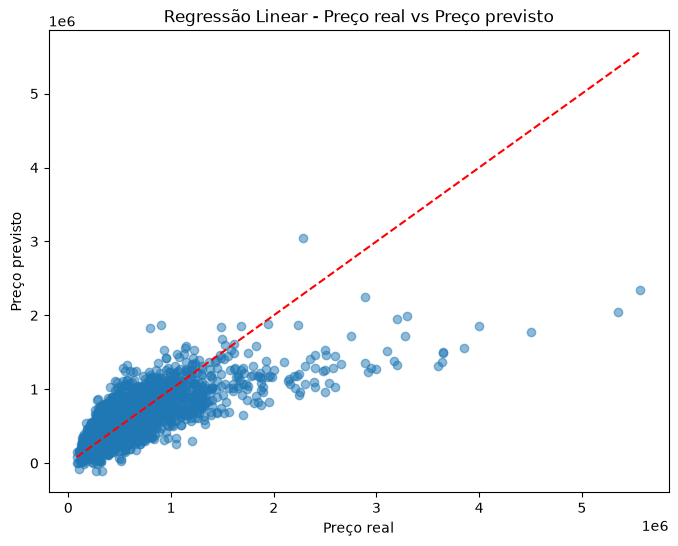

In [53]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Preço real")
plt.ylabel("Preço previsto")
plt.title("Regressão Linear - Preço real vs Preço previsto")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

Notase que utilizando apenas as variáveis selecionadas na análise explorátoria, o modelo teve um desempenho melhor:

MAE (Erro Médio Absoluto): Quanto o modelo erra em média de 238 mil para 167 mil.
RMSE (Raiz do Erro Quadrático Médio): Quanto o modelo erra (penalizando erros maiores) em média de 387 mil para 264 mil.
R² (Coeficiente de Determinação): Capacidade de explicar o preço de 0.0077 para 0.5384.

O modelo tem dificuldade com imóveis com preços maiores

In [ ]:
X = df[[
    "area_habitavel",
    "padrao_construcao",
    "area_habitavel_vizinhos"
]]
y = df["preco"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Calcular limites usando apenas o treinamento
Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)
diq = Q3 - Q1

limite_inferior = Q1 - 1.5 * diq
limite_superior = Q3 + 1.5 * diq

mascara = y_train.between(limite_inferior, limite_superior)

# Modelo com outliers
modelo_com = LinearRegression()
modelo_com.fit(X_train, y_train)

# Modelo sem outliers no treinamento
modelo_sem = LinearRegression()
modelo_sem.fit(X_train.loc[mascara], y_train.loc[mascara])

# Avaliação no mesmo teste
for nome, modelo in [
    ("Com outliers", modelo_com),
    ("Sem outliers", modelo_sem)
]:
    previsoes = modelo.predict(X_test)

    print(f"\n{nome}")
    print(f"MAE: R$ {mean_absolute_error(y_test, previsoes):,.2f}")
    print(f"RMSE: R$ {mean_squared_error(y_test, previsoes)**0.5:,.2f}")
    print(f"R²: {r2_score(y_test, previsoes):.4f}")


Com outliers
MAE: R$ 167,660.66
RMSE: R$ 264,168.48
R²: 0.5384

Sem outliers
MAE: R$ 161,520.49
RMSE: R$ 292,485.18
R²: 0.4341
